# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'ym31'
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

rng = np.random.default_rng(457)

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

(1) WLS: k = 0.2432 +/- 0.0097 mag/airmass (quoted errors only), m0 = 25.066 +/- 0.016 mag
(2) polyfit cov=True:       k = 0.2432 +/- 0.0221
    polyfit cov='unscaled': k = 0.2432 +/- 0.0097  (same as my WLS)
(3) chi2 = 67.2 for 13 dof, chi2/dof = 5.17 (expect 1 +/- 0.39)
    polyfit error / WLS error = 2.273;  sqrt(chi2/dof) = 2.273
    P(chi2 >= this | quoted errors right) = 2.6e-09
    P(chi2 <= this | quoted errors right) = 0.9999999974
(4) normalized residuals: std = 2.27, MAD-sigma = 2.05, |r|>2 for 4 of 15 points, worst = -5.2
    without the worst point: k = 0.2550, chi2/dof = 3.10, rescaled sigma_k = 0.0176
    jackknife sigma_k = 0.0220


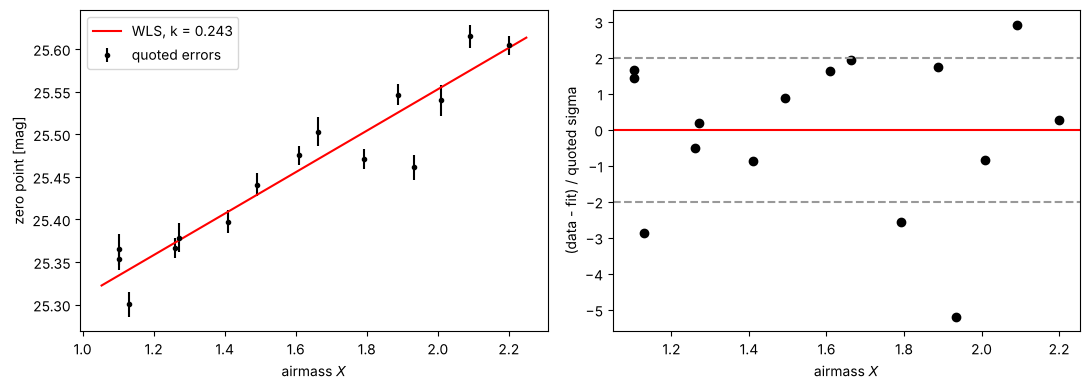

In [2]:
# 1a: your work here
d = load('p1a_extinction')
X, zp, sq = d['airmass'].to_numpy(), d['zeropoint_mag'].to_numpy(), d['sigma_quoted_mag'].to_numpy()
n = len(X)

def wls(A, y, sy):
    Si = np.diag(1 / sy**2)
    cov = np.linalg.inv(A.T @ Si @ A)
    return cov @ A.T @ Si @ y, cov

# (1) weighted least squares with the quoted errors, by hand
A = np.vstack([X, np.ones(n)]).T
(k, m0), cov_q = wls(A, zp, sq)
sk_q = np.sqrt(cov_q[0, 0])
print(f"(1) WLS: k = {k:.4f} +/- {sk_q:.4f} mag/airmass (quoted errors only), m0 = {m0:.3f} +/- {np.sqrt(cov_q[1,1]):.3f} mag")

# (2) polyfit with cov=True
p_pf, cov_pf = np.polyfit(X, zp, 1, w=1/sq, cov=True)
p_un, cov_un = np.polyfit(X, zp, 1, w=1/sq, cov='unscaled')
sk_pf = np.sqrt(cov_pf[0, 0])
print(f"(2) polyfit cov=True:       k = {p_pf[0]:.4f} +/- {sk_pf:.4f}")
print(f"    polyfit cov='unscaled': k = {p_un[0]:.4f} +/- {np.sqrt(cov_un[0,0]):.4f}  (same as my WLS)")

# (3) chi^2
r = (zp - A @ np.array([k, m0])) / sq
chi2 = np.sum(r**2); dof = n - 2
print(f"(3) chi2 = {chi2:.1f} for {dof} dof, chi2/dof = {chi2/dof:.2f} (expect 1 +/- {np.sqrt(2/dof):.2f})")
print(f"    polyfit error / WLS error = {sk_pf/sk_q:.3f};  sqrt(chi2/dof) = {np.sqrt(chi2/dof):.3f}")
print(f"    P(chi2 >= this | quoted errors right) = {stats.chi2.sf(chi2, dof):.1e}")
print(f"    P(chi2 <= this | quoted errors right) = {stats.chi2.cdf(chi2, dof):.10f}")

# (4) is it a few outliers or all the errors? look at the normalized residuals
mad_sig = 1.4826 * np.median(np.abs(r - np.median(r)))
print(f"(4) normalized residuals: std = {np.std(r, ddof=2):.2f}, MAD-sigma = {mad_sig:.2f}, "
      f"|r|>2 for {np.sum(np.abs(r) > 2)} of {n} points, worst = {r[np.argmax(np.abs(r))]:+.1f}")
# drop the single worst point and refit, to see if it is driving chi2
keep = np.abs(r) < np.abs(r).max()
(k_d, _), cov_d = wls(A[keep], zp[keep], sq[keep])
r_d = (zp[keep] - A[keep] @ wls(A[keep], zp[keep], sq[keep])[0]) / sq[keep]
chi2_d = np.sum(r_d**2)
print(f"    without the worst point: k = {k_d:.4f}, chi2/dof = {chi2_d/(n-3):.2f}, "
      f"rescaled sigma_k = {np.sqrt(cov_d[0,0]*chi2_d/(n-3)):.4f}")
# jackknife as an independent check of the error on k that doesn't use the quoted errors' size
k_jk = np.array([wls(np.delete(A, i, 0), np.delete(zp, i), np.delete(sq, i))[0][0] for i in range(n)])
sk_jk = np.sqrt((n - 1) / n * np.sum((k_jk - k_jk.mean())**2))
print(f"    jackknife sigma_k = {sk_jk:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(X.min() - 0.05, X.max() + 0.05, 100)
ax[0].errorbar(X, zp, sq, fmt='k.', label='quoted errors')
ax[0].plot(xx, k*xx + m0, 'r-', label=f'WLS, k = {k:.3f}')
ax[0].set_xlabel('airmass $X$'); ax[0].set_ylabel('zero point [mag]'); ax[0].legend()
ax[1].plot(X, r, 'ko'); ax[1].axhline(0, color='r')
for s_ in (-2, 2): ax[1].axhline(s_, color='0.6', ls='--')
ax[1].set_xlabel('airmass $X$'); ax[1].set_ylabel('(data - fit) / quoted sigma')
plt.tight_layout(); plt.show()

**ANSWER:**

1. Weighted least squares with the quoted errors gives $k = 0.2432 \pm 0.0097$ mag/airmass (and $m_0 = 25.066 \pm 0.016$ mag). That error is $\sqrt{[(A^T\Sigma^{-1}A)^{-1}]_{00}}$, so it only knows about the quoted $\sigma_i$.

2. `np.polyfit(..., w=1/sigma, cov=True)` gives the same $k$ but $\pm 0.0221$ mag/airmass, 2.27 times bigger. With `cov=True` numpy does not trust the weights as real errors: it multiplies the covariance by $\chi^2/(N - \mathrm{deg} - 1) = \chi^2/13$, i.e. it rescales the errors until $\chi^2_{\rm red} = 1$. The ratio of the two error bars is exactly $\sqrt{\chi^2/\nu} = 2.273$. `cov='unscaled'` gives back my 0.0097.

3. $\chi^2 = 67.2$ for $\nu = 15 - 2 = 13$ dof, so $\chi^2/\nu = 5.2$, when a good fit should give $1 \pm 0.39$. If the quoted errors were right, the chance of a $\chi^2$ at least this large is $P = 2.6\times10^{-9}$ (`stats.chi2.sf`); the chance of one this small or smaller is essentially 1, so it is not suspiciously small, it is far too large.

4. I'd quote $k = 0.243 \pm 0.022$ mag/airmass. Rescaling to $\chi^2_{\rm red}=1$ is circular if you use it to claim the model fits, but here I'm not testing the model: extinction linear in airmass is the physics, and the question is only how big the real errors are. Before rescaling I checked the residuals to see whether one or two outliers are behind the big $\chi^2$ (the Cepheid lesson): they aren't. The normalized residuals have std 2.27 and a robust MAD-$\sigma$ of 2.05, so the whole distribution is about twice too wide, not just a tail. The worst point is at $-5.2\sigma$; dropping it changes $k$ to 0.255 and still leaves $\chi^2/\nu = 3.1$ (rescaled $\sigma_k = 0.018$), so it doesn't explain it. A jackknife, which doesn't use the size of the quoted errors at all, gives $\sigma_k = 0.022$, the same as the rescaled number. So the pipeline's error bars are underestimated by about a factor of 2 (probably a missing systematic term, e.g. flat-fielding or transparency changes through the night), and the quoted-error-only 0.0097 is over-confident by that factor.


### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [3]:
# 1b: your work here
d = load('p1b_centroid')
s_psf, N, s_quoted = d['psf_sigma_arcsec'][0], d['n_photons'][0], d['quoted_sigma_x0_arcsec'][0]
# Gaussian PSF: Fisher information per photon is 1/s_psf^2, so I = N/s_psf^2 and the bound is s_psf/sqrt(N)
crb = s_psf / np.sqrt(N)
print(f"PSF sigma = {s_psf:.3f} arcsec, N = {N} photons")
print(f"Cramer-Rao bound: sigma_x0 >= {crb:.4f} arcsec")
print(f"quoted: {s_quoted:.4f} arcsec = {s_quoted/crb:.2f} x the bound")

# check the bound by simulation: the sample mean is unbiased and efficient for a Gaussian PSF
xhat = rng.normal(0, s_psf, size=(20000, N)).mean(axis=1)
print(f"scatter of the sample mean over 20000 fake stars: {xhat.std():.4f} arcsec")
# what simple mistakes give the quoted number?
print(f"if each photon is counted twice (N -> 2N): {s_psf/np.sqrt(2*N):.4f} arcsec")
print(f"photons needed to really reach the quoted error: {(s_psf/s_quoted)**2:.0f}")

PSF sigma = 1.316 arcsec, N = 396 photons
Cramer-Rao bound: sigma_x0 >= 0.0661 arcsec
quoted: 0.0450 arcsec = 0.68 x the bound


scatter of the sample mean over 20000 fake stars: 0.0665 arcsec
if each photon is counted twice (N -> 2N): 0.0467 arcsec
photons needed to really reach the quoted error: 854


**ANSWER:**

1. For photons drawn from a Gaussian PSF of width $\sigma_{\rm PSF}$, each photon carries Fisher information $1/\sigma_{\rm PSF}^2$ about the position, so $I = N/\sigma_{\rm PSF}^2$ and the Cramér-Rao bound is $\sigma_{x_0} \ge \sigma_{\rm PSF}/\sqrt{N} = 1.316/\sqrt{396} = 0.066$ arcsec. The plain sample mean already reaches it (my 20000 fake stars give 0.0665 arcsec), so no weighting scheme can do better for an unbiased estimator.

2. No. The quoted 0.045 arcsec is 0.68 times the bound; to really get there you'd need about 850 photons, not 396. So the number can't be the error of an unbiased position estimate. Either the estimator is biased (e.g. a weighting that pulls toward the starting guess or the window centre has a smaller scatter, but then its real error, the bias plus the scatter, is bigger and the quoted number leaves the bias out), or it is just a mistake. Two concrete mistakes that would give something this small:
   - **counting each photon twice** (e.g. summing over photons and over pixels, or treating weights as extra counts): $N \to 2N$ gives $1.316/\sqrt{792} = 0.047$ arcsec, almost exactly their number;
   - **computing the error with the true position plugged in** (testing the weighting scheme on simulations where the weights were centred on the known answer), which uses information the real measurement doesn't have.
   (Mixing up FWHM and $\sigma$ would go the other way, FWHM is $2.35\sigma$, so it would make the error bigger, not smaller.)


### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

best depth = 2.402 ppt, d2(-2lnL)/d depth^2 = 32.07 ppt^-2
classmate: sigma = 0.177 ppt;  correct: sigma = sqrt(2/curv) = 0.250 ppt;  ratio = 1.414
Delta(-2lnL)=1 interval: [2.150, 2.649] ppt  ->  2.402 -0.253 +0.247 ppt
predicted coverage of the classmate's intervals: P(|z| < 1/sqrt2) = 0.520
simulated (5000 datasets): classmate 0.519, correct sigma 0.686  (binomial scatter +/- 0.007)


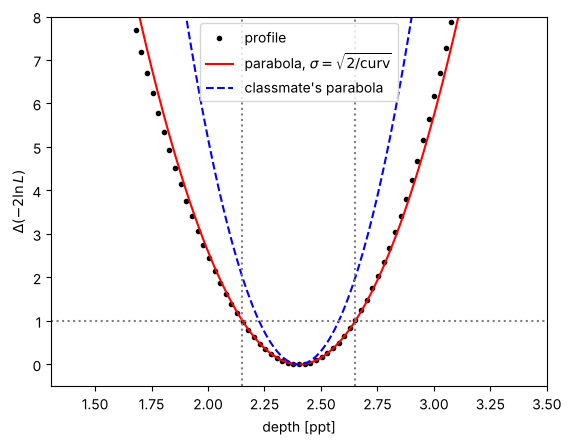

In [4]:
# 1c: your work here
d = load('p1c_profile')
dep, m2l = d['depth_ppt'].to_numpy(), d['minus2lnL'].to_numpy()
i0 = np.argmin(m2l)
# fit a parabola to the points near the minimum to get the best depth and the curvature
sel = slice(max(i0 - 5, 0), i0 + 6)
a2, a1, a0 = np.polyfit(dep[sel], m2l[sel], 2)
best = -a1 / (2*a2); curv = 2*a2              # d^2(-2lnL)/d depth^2
sig_classmate = 1 / np.sqrt(curv)
sig_right = np.sqrt(2 / curv)                   # factor 2: -2lnL is chi^2, not -lnL
print(f"best depth = {best:.3f} ppt, d2(-2lnL)/d depth^2 = {curv:.2f} ppt^-2")
print(f"classmate: sigma = {sig_classmate:.3f} ppt;  correct: sigma = sqrt(2/curv) = {sig_right:.3f} ppt;  ratio = {sig_right/sig_classmate:.3f}")

# (2) read the Delta(-2lnL) = 1 interval straight off the profile (linear interpolation)
from scipy.optimize import brentq
m2l_min = a0 - a1**2 / (4*a2)
f = lambda t: np.interp(t, dep, m2l) - m2l_min - 1
lo, hi = brentq(f, dep[0], best), brentq(f, best, dep[-1])
print(f"Delta(-2lnL)=1 interval: [{lo:.3f}, {hi:.3f}] ppt  ->  {best:.3f} -{best-lo:.3f} +{hi-best:.3f} ppt")

# (3) coverage of the classmate's +/- sigma
pred = 2*stats.norm.cdf(1/np.sqrt(2)) - 1
truth = 2.40                                     # a truth I choose
fake = rng.normal(truth, sig_right, 5000)        # fake best-fit depths
cov_cl = np.mean(np.abs(fake - truth) < sig_classmate)
cov_ok = np.mean(np.abs(fake - truth) < sig_right)
print(f"predicted coverage of the classmate's intervals: P(|z| < 1/sqrt2) = {pred:.3f}")
print(f"simulated (5000 datasets): classmate {cov_cl:.3f}, correct sigma {cov_ok:.3f}  "
      f"(binomial scatter +/- {np.sqrt(0.68*0.32/5000):.3f})")

xx = np.linspace(dep.min(), dep.max(), 300)
plt.plot(dep, m2l - m2l_min, 'k.', label='profile')
plt.plot(xx, (xx - best)**2 / sig_right**2, 'r-', label=r'parabola, $\sigma=\sqrt{2/{\rm curv}}$')
plt.plot(xx, (xx - best)**2 / sig_classmate**2, 'b--', label="classmate's parabola")
plt.axhline(1, color='0.5', ls=':'); plt.axvline(lo, color='0.5', ls=':'); plt.axvline(hi, color='0.5', ls=':')
plt.ylim(-0.5, 8); plt.xlabel('depth [ppt]'); plt.ylabel(r'$\Delta(-2\ln L)$'); plt.legend(); plt.show()

**ANSWER:**

1. A parabola fit to the profile near its minimum gives the best depth 2.402 ppt and curvature $d^2(-2\ln L)/d\,\mathrm{depth}^2 = 32.1$ ppt$^{-2}$. Since $-2\ln L \approx \mathrm{const} + (\delta - \hat\delta)^2/\sigma^2$, its second derivative is $2/\sigma^2$, so the right error is $\sigma = \sqrt{2/32.1} = 0.25$ ppt. The classmate's $1/\sqrt{32.1} = 0.18$ ppt is too small by a factor $\sqrt 2 = 1.41$: they used the formula for the curvature of $-\ln L$ on $-2\ln L$ (the factor of 2 we keep in `cov = 2*inv(H)`). Best depth: $2.40 \pm 0.25$ ppt.

2. Reading off $\Delta(-2\ln L) = 1$ directly gives $[2.150, 2.649]$ ppt, i.e. $2.40^{+0.25}_{-0.25}$ ppt ($-0.253$, $+0.247$). It is symmetric to within 0.006 ppt and matches the curvature answer, so the profile is very close to a parabola near the minimum and the curvature error is fine at $1\sigma$. Further out it does get lopsided: at $\Delta(-2\ln L) = 9$ (3$\sigma$) the interval is $-0.79$/$+0.72$ ppt, wider on the shallow side, so for a 3$\sigma$ limit I'd read it off the profile rather than use the parabola; the classmate's problem is only the factor of 2. (One more caveat: this profile was computed with the other parameters fixed at their best values, so strictly it's a conditional slice; if the depth is correlated with e.g. the duration or baseline, the marginal error would be a bit bigger still, cf. 1e.)

3. $\pm\sigma/\sqrt2$ is $\pm 0.707$ of the true $\sigma$, so the coverage should be $P(|z| < 1/\sqrt2) = 52\%$, not 68%. Simulating 5000 best-fit depths around a truth of 2.40 ppt with the correct $\sigma$: the classmate's intervals contain the truth 51.9% of the time, and the correct ones 68.6% (binomial scatter $\pm 0.7\%$). So about half of their intervals would miss the truth.


### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

M2 = 10.3 +3.5 / -2.6 Msun (median, 16th-84th percentiles)
(i)   variance         = 10.6 Msun^2   -> not even in Msun; sqrt would be 3.25 Msun
(ii)  p84 - p16        = 6.12 Msun     -> full 68% width, 2.00 x the half-width 3.06 Msun
(iii) std/sqrt(8000)   = 0.036 Msun    -> Monte Carlo error on the mean, 84 x too small
mean = 10.79, median = 10.32, mode ~ 9.7 Msun;  skewness = 0.96
upper error / lower error = 1.33
   2.5th percentile: samples 5.8,  symmetric Gaussian 4.1 Msun
  97.5th percentile: samples 18.3,  symmetric Gaussian 16.3 Msun


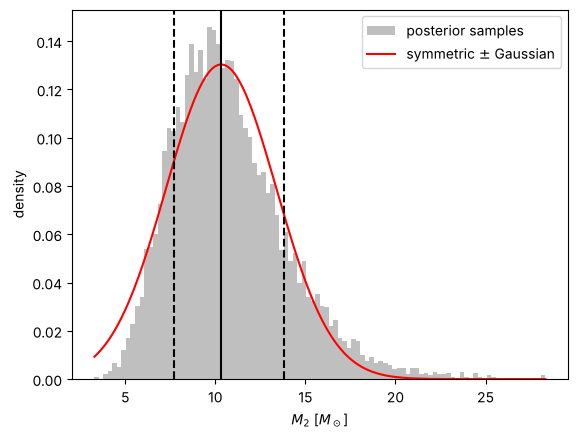

In [5]:
# 1d: your work here
M2 = load('p1d_mass_samples')['M2_Msun'].to_numpy()
lo, med, hi = np.percentile(M2, [16, 50, 84])
print(f"M2 = {med:.1f} +{hi-med:.1f} / -{med-lo:.1f} Msun (median, 16th-84th percentiles)")
sig_half = (hi - lo) / 2                         # half the 68% width, the closest thing to a 1 sigma
v, w, sem = M2.var(ddof=1), hi - lo, M2.std(ddof=1)/np.sqrt(M2.size)
print(f"(i)   variance         = {v:.1f} Msun^2   -> not even in Msun; sqrt would be {np.sqrt(v):.2f} Msun")
print(f"(ii)  p84 - p16        = {w:.2f} Msun     -> full 68% width, {w/sig_half:.2f} x the half-width {sig_half:.2f} Msun")
print(f"(iii) std/sqrt(8000)   = {sem:.3f} Msun    -> Monte Carlo error on the mean, {sig_half/sem:.0f} x too small")
print(f"mean = {M2.mean():.2f}, median = {med:.2f}, mode ~ ", end='')
h, e = np.histogram(M2, 80); print(f"{0.5*(e[h.argmax()]+e[h.argmax()+1]):.1f} Msun;  skewness = {stats.skew(M2):.2f}")
print(f"upper error / lower error = {(hi-med)/(med-lo):.2f}")
# a symmetric Gaussian with the same median and sigma would put this much mass below zero / at low masses:
g = rng.normal(med, sig_half, M2.size)
for q in (2.5, 97.5):
    print(f"  {q:>4}th percentile: samples {np.percentile(M2, q):.1f},  symmetric Gaussian {np.percentile(g, q):.1f} Msun")

plt.hist(M2, 100, density=True, color='0.75', label='posterior samples')
xx = np.linspace(M2.min(), M2.max(), 300)
plt.plot(xx, stats.norm.pdf(xx, med, sig_half), 'r-', label=r'symmetric $\pm$ Gaussian')
for q in (lo, med, hi): plt.axvline(q, color='k', ls='--' if q != med else '-')
plt.xlabel(r'$M_2$ [$M_\odot$]'); plt.ylabel('density'); plt.legend(); plt.show()

**ANSWER:**

1. $M_2 = 10.3^{+3.5}_{-2.6}\ M_\odot$ (median, 16th-84th percentiles).

2. Taking a "$1\sigma$" of about 3 $M_\odot$ (half the 16-84 width is 3.06 $M_\odot$):
   - (i) The variance, 10.6 $M_\odot^2$, isn't an error bar at all, it has units of $M_\odot^2$. Its square root (the std, 3.25 $M_\odot$) would be roughly right, but the variance as quoted is off by a factor of about 3.5 and in the wrong units.
   - (ii) The 84th minus the 16th percentile, 6.1 $M_\odot$, is the full width of the 68% interval, so as a $\pm 1\sigma$ it's 2 times too big.
   - (iii) std$/\sqrt{8000}$ = 0.036 $M_\odot$ is the Monte Carlo error on the posterior mean, i.e. how well the 8000 samples pin down the mean, not how well the data pin down the mass. It's about 84 times too small and would keep shrinking as you ran the chain longer.

3. No. The posterior is skewed to high masses (skewness 0.96; the mean 10.8 is above the median 10.3, which is above the mode near 9.7 $M_\odot$), and the upper error is 1.33 times the lower one. The tails show it best: the 2.5th and 97.5th percentiles of the samples are 5.8 and 18.3 $M_\odot$, while a symmetric Gaussian with the same median and width puts them at 4.1 and 16.3 $M_\odot$, so a $\pm$ error bar overstates how low the mass could be and understates how high. Quote the asymmetric $^{+3.5}_{-2.6}$ (plot above).


### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

rho = -0.851
marginal sigma_slope = 0.0490;  conditional (fixed intercept) = 0.0257  [thin slice of 455 samples: 0.0255]
ratio cond/marg = 0.526;  sqrt(1 - rho^2) = 0.525


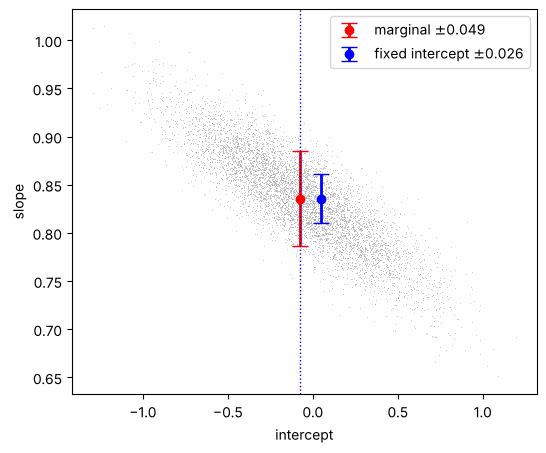

In [6]:
# 1e: your work here
d = load('p1e_slope_intercept_samples')
a, b = d['slope'].to_numpy(), d['intercept'].to_numpy()
rho = np.corrcoef(a, b)[0, 1]
sig_marg = a.std(ddof=1)
# slope at fixed intercept: remove the part of the slope that follows the intercept
# (the residual scatter of slope about its linear regression on intercept)
slope_on_b = np.cov(a, b)[0, 1] / b.var(ddof=1)
sig_cond = np.std(a - slope_on_b*(b - b.mean()), ddof=2)
# same thing directly: the samples whose intercept is within a thin slice of its best value
b0 = np.median(b); sl = np.abs(b - b0) < 0.1*b.std()
print(f"rho = {rho:.3f}")
print(f"marginal sigma_slope = {sig_marg:.4f};  conditional (fixed intercept) = {sig_cond:.4f}  "
      f"[thin slice of {sl.sum()} samples: {a[sl].std(ddof=1):.4f}]")
print(f"ratio cond/marg = {sig_cond/sig_marg:.3f};  sqrt(1 - rho^2) = {np.sqrt(1 - rho**2):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(b, a, ',', color='0.6', alpha=0.5)
a_med = np.median(a)
ax.errorbar(b0, a_med, yerr=sig_marg, fmt='o', color='r', capsize=6, lw=2, label=rf'marginal $\pm${sig_marg:.3f}')
ax.errorbar(b0 + 0.05*np.ptp(b), a_med, yerr=sig_cond, fmt='o', color='b', capsize=6, lw=2,
            label=rf'fixed intercept $\pm${sig_cond:.3f}')
ax.axvline(b0, color='b', ls=':', lw=1)
ax.set_xlabel('intercept'); ax.set_ylabel('slope'); ax.legend(); plt.show()

**ANSWER:**

1. The marginal error on the slope (intercept marginalized over, just the spread of the slope column) is 0.049. The classmate's error, the spread of the slope at fixed intercept, is 0.026; I got it from the scatter of the slope about its linear regression on the intercept, and checked it with the samples in a thin slice around the median intercept (0.0255, same thing).

2. The ratio is 0.53, and the correlation coefficient is $\rho = -0.85$. For a 2-D Gaussian the conditional width is $\sigma_{\rm marg}\sqrt{1-\rho^2}$, and $\sqrt{1 - 0.851^2} = 0.53$, matching. So the stronger the correlation, the more fixing the intercept shrinks the slope error (it goes to zero as $|\rho| \to 1$). Fixing the intercept is the same as taking $1/\sqrt{I_{ii}}$ instead of inverting the whole Fisher matrix first. The plot shows both error bars on the samples: the red (marginal) one spans the whole cloud in slope, the blue (fixed intercept) one only the thin vertical slice through it.

3. The classmate's number is only right if the intercept is actually known exactly from somewhere else; otherwise (and here it isn't) quote the marginal 0.049.


## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

In [7]:
# 2a: your work here

**ANSWER:**

*your answer goes here*

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

In [8]:
# 2b: your work here

**ANSWER:**

*your answer goes here*

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [9]:
# 2c: your work here

**ANSWER:**

*your answer goes here*

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [10]:
# 2d: your work here

**ANSWER:**

*your answer goes here*

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

In [11]:
# 2e: your work here

**ANSWER:**

*your answer goes here*

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [12]:
# 3a: your work here

**REFEREE REPORT:**

*your report goes here*

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

*your answer goes here*

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.